# 02 – Federated Learning (IID)

Objective:
- Train the MLP in a federated setting using FedAvg.
- Use IID partitions with 2, 5, 10 and 20 clients.
- Compare FL to:
  - Centralized baseline
  - Local training baseline
- Tune FL parameters until performance approaches centralized training.

## 1. Load Dataset

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data import load_dataset
from partition import iid_partition
from fl import run_fedavg

In [2]:
SEED = 42

np.random.seed(SEED)

In [3]:
d = load_dataset(
    val_size=0.15,
    seed=SEED,
)

X_tr = d["X_train"]
y_tr = d["y_train"]

X_va = d["X_val"]
y_va = d["y_val"]

X_te = d["X_test"]
y_te = d["y_test"]

print("Train:", X_tr.shape)
print("Valid:", X_va.shape)
print("Test :", X_te.shape)

Train: (27676, 89)
Valid: (4885, 89)
Test : (16281, 89)


## 2. Load Baselines

In [4]:
baseline_file = Path("results/01_baselines.json")

baseline = json.loads(
    baseline_file.read_text()
)

baseline

{'central': {'runs': [{'loss': 0.31694319937581117,
    'accuracy': 0.85418586081936,
    'balanced_acc': 0.7658086323452938,
    'f1': 0.6596903669724771,
    'roc_auc': 0.9064930775759378,
    'seed': 42,
    'epochs': 23},
   {'loss': 0.31558052764783723,
    'accuracy': 0.8554142865917327,
    'balanced_acc': 0.7669719985421853,
    'f1': 0.6619758759333716,
    'roc_auc': 0.9071547920219984,
    'seed': 43,
    'epochs': 22},
   {'loss': 0.31708873322804826,
    'accuracy': 0.8539401756648854,
    'balanced_acc': 0.7626845242687874,
    'f1': 0.6560601677755279,
    'roc_auc': 0.9063715825673639,
    'seed': 44,
    'epochs': 21}],
  'mean': {'accuracy': 0.854513441025326,
   'balanced_acc': 0.7651550517187555,
   'f1': 0.6592421368937922,
   'roc_auc': 0.9066731507217668},
  'std': {'accuracy': 0.000789767275637689,
   'balanced_acc': 0.0022172019839883624,
   'f1': 0.0029832169556995056,
   'roc_auc': 0.0004215139568789726}},
 'reference': {'MLP (unser Modell)': {'accuracy': 0.8

In [5]:
central_acc = baseline["central"]["mean"]["accuracy"]
central_f1 = baseline["central"]["mean"]["f1"]
central_auc = baseline["central"]["mean"]["roc_auc"]

print("Centralized Accuracy:", central_acc)
print("Centralized F1      :", central_f1)
print("Centralized ROC-AUC :", central_auc)

Centralized Accuracy: 0.854513441025326
Centralized F1      : 0.6592421368937922
Centralized ROC-AUC : 0.9066731507217668


## 3. Experiment Configuration

In [6]:
CLIENT_CONFIGS = [2, 5, 10, 20]

ROUNDS = 20
LOCAL_EPOCHS = 20
LR = 1e-3
BATCH_SIZE = 64

## 4. Run IID Experiments

In [8]:
results = {}

for n_clients in CLIENT_CONFIGS:

    print("=" * 60)
    print(f"FEDAVG WITH {n_clients} CLIENTS")
    print("=" * 60)

    parts = iid_partition(
        y_tr,
        n_clients=n_clients,
        seed=SEED,
    )

    history = run_fedavg(
        X_train=X_tr,
        y_train=y_tr,
        X_test=X_te,
        y_test=y_te,
        partitions=parts,
        rounds=ROUNDS,
        local_epochs=LOCAL_EPOCHS,
        lr=LR,
        batch_size=BATCH_SIZE,
    )

    results[n_clients] = pd.DataFrame(history)

    print()



	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=20, no round_timeout


FEDAVG WITH 2 CLIENTS


2026-11-27 10:49:11,934	INFO worker.py:2038 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'node:127.0.0.1': 1.0, 'GPU': 1.0, 'memory': 2267459175.0, 'node:__internal_head__': 1.0, 'object_store_memory': 971768217.0, 'accelerator_type:GeForce-MX450': 1.0, 'CPU': 8.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 1}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 8 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
INFO :      Received initial parameters from one random client
INFO :      Starting evaluation of initial global parameters
INFO :      initial parameters (loss, other metrics): 0.6937426154139469, {'accuracy': 0.4905718321970395, 'balanced_acc': 0.5601872325797737, 'f1': 0.39095315024232635, 'roc_auc': 0.5857631394117848}
INFO :      
I

Round   0 | Acc=0.4906 F1=0.3910 AUC=0.5858


INFO :      aggregate_fit: received 2 results and 0 failures
INFO :      fit progress: (1, 0.3239448849701583, {'accuracy': 0.8504391622136233, 'balanced_acc': 0.7559925967605652, 'f1': 0.6457151171249819, 'roc_auc': 0.9031157756161473}, 38.063149599998724)
INFO :      configure_evaluate: strategy sampled 2 clients (out of 2)


Round   1 | Acc=0.8504 F1=0.6457 AUC=0.9031


... (82 outputs left out)

INFO :      aggregate_evaluate: received 5 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 20 round(s) in 413.53s
INFO :      	History (loss, distributed):
INFO :      		round 1: 0.3160349346386188
INFO :      		round 2: 0.3105780167185525
INFO :      		round 3: 0.30574587478376725
INFO :      		round 4: 0.30103357836127836
INFO :      		round 5: 0.29975902857330083
INFO :      		round 6: 0.29877717809430254
INFO :      		round 7: 0.2979417273805418
INFO :      		round 8: 0.29559261163170236
INFO :      		round 9: 0.29720493076891286
INFO :      		round 10: 0.29706379075068695
INFO :      		round 11: 0.29704997261978383
INFO :      		round 12: 0.2961062005008995
INFO :      		round 13: 0.29935244990061555
INFO :      		round 14: 0.2976298117180534
INFO :      		round 15: 0.2945623535149038
INFO :      		round 16: 0.29793150346027986
INFO :      		round 17: 0.29748077013082264
INFO :      		round 18: 0.29716788612651485
INFO :      		round 19: 0.297247


FEDAVG WITH 10 CLIENTS


2026-11-27 11:07:29,916	INFO node.py:438 -- Failed to get node info b'GCS cannot find the node with node ID 1e26453be7b7832a55506e9fac4da2d23a6694e622b8f17aebd5c49b. The node registration may not be complete yet before the timeout. Try increase the RAY_raylet_start_wait_time_s config.'


Exception: The current node timed out during startup. This could happen because some of the raylet failed to startup or the GCS has become overloaded.

Inspecting Final Round

In [9]:
summary_rows = []

for n_clients, hist in results.items():

    last = hist.iloc[-1]

    summary_rows.append(
        {
            "clients": n_clients,
            "accuracy": last["accuracy"],
            #"balanced_accuracy": last["balanced_accuracy"],
            "f1": last["f1"],
            "roc_auc": last["roc_auc"],
            "loss": last["loss"],
        }
    )

summary = pd.DataFrame(summary_rows)

summary.round(4)

,clients,accuracy,f1,roc_auc,loss
0,2,0.8524,0.6608,0.9030,0.3240
1,5,0.8506,0.6546,0.9030,0.3224
2,10,0.8511,0.6609,0.9029,0.3231
3,20,0.8505,0.6624,0.9020,0.3252


## 5. Plot Accuracy Curves

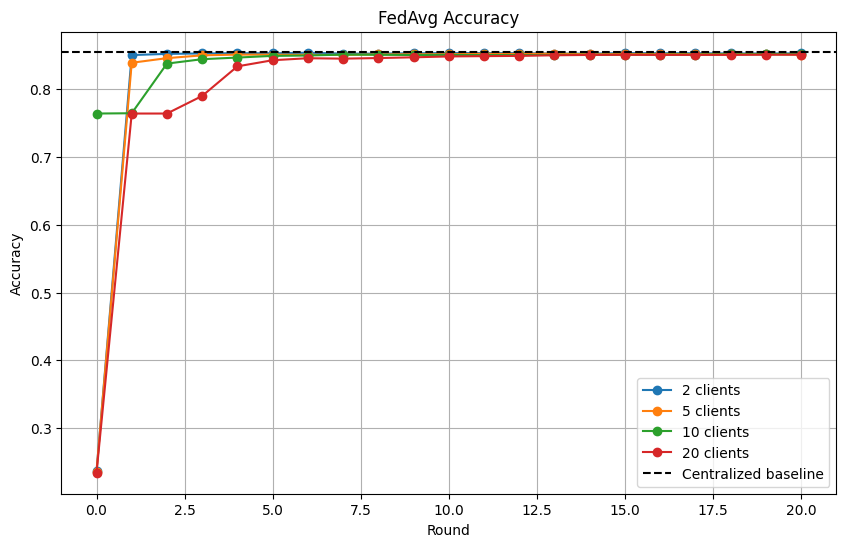

In [10]:
plt.figure(figsize=(10, 6))

for n_clients, hist in results.items():

    plt.plot(
        hist["round"],
        hist["accuracy"],
        marker="o",
        label=f"{n_clients} clients",
    )

plt.axhline(
    central_acc,
    linestyle="--",
    color="black",
    label="Centralized baseline",
)

plt.xlabel("Round")
plt.ylabel("Accuracy")
plt.title("FedAvg Accuracy")
plt.legend()
plt.grid(True)

plt.show()

## 6. Plot F1 Convergence

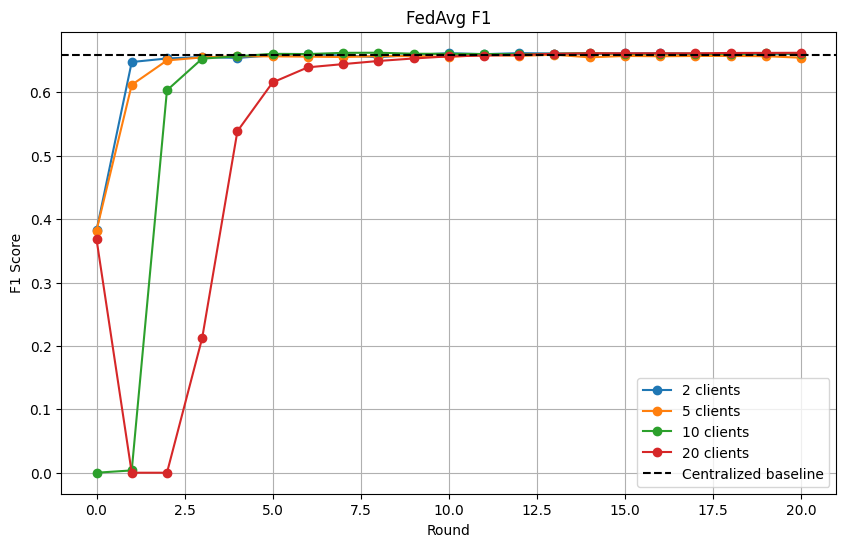

In [11]:
plt.figure(figsize=(10, 6))

for n_clients, hist in results.items():

    plt.plot(
        hist["round"],
        hist["f1"],
        marker="o",
        label=f"{n_clients} clients",
    )

plt.axhline(
    central_f1,
    linestyle="--",
    color="black",
    label="Centralized baseline",
)

plt.xlabel("Round")
plt.ylabel("F1 Score")
plt.title("FedAvg F1")
plt.legend()
plt.grid(True)

plt.show()

## 7. ROC-AUC Curves

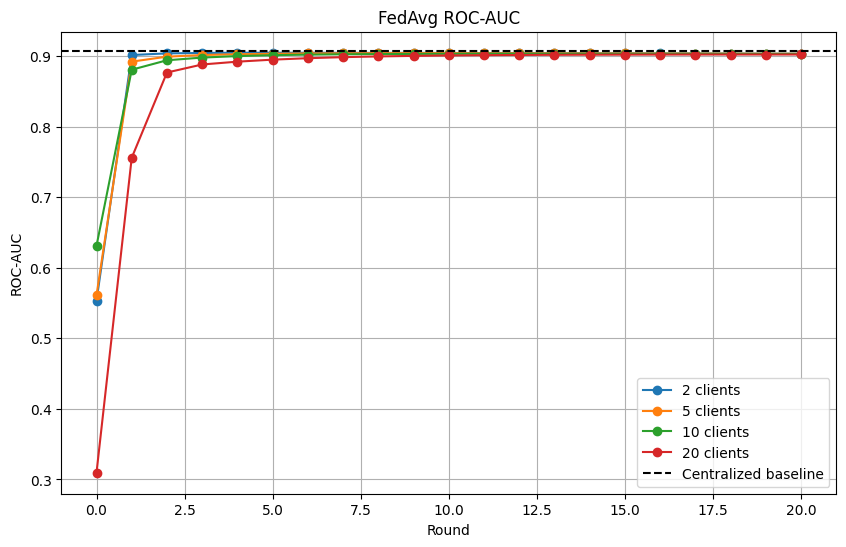

In [12]:
plt.figure(figsize=(10, 6))

for n_clients, hist in results.items():

    plt.plot(
        hist["round"],
        hist["roc_auc"],
        marker="o",
        label=f"{n_clients} clients",
    )

plt.axhline(
    central_auc,
    linestyle="--",
    color="black",
    label="Centralized baseline",
)

plt.xlabel("Round")
plt.ylabel("ROC-AUC")
plt.title("FedAvg ROC-AUC")
plt.legend()
plt.grid(True)

plt.show()

## 7. Hyperparameter Tuning

In [17]:
search = [
    {"rounds": 20, "epochs": 1, "lr": 1e-3},
    {"rounds": 10, "epochs": 1, "lr": 1e-3},
    {"rounds": 20, "epochs": 2, "lr": 1e-3},
    {"rounds": 20, "epochs": 1, "lr": 5e-4},
]

additional parameters

In [ ]:
search_epochs = [
    {"rounds": 20, "epochs": 10, "lr": 1e-3},
    {"rounds": 10, "epochs": 20, "lr": 1e-3},
    {"rounds": 20, "epochs": 20, "lr": 5e-4},
]

## 8. Parameter Search on 5 Clients

In [18]:
tuning_results = []

parts = iid_partition(
    y_tr,
    n_clients=5,
    seed=SEED,
)

for cfg in search:

    print(cfg)

    hist = run_fedavg(
        X_train=X_tr,
        y_train=y_tr,
        X_test=X_te,
        y_test=y_te,
        partitions=parts,
        rounds=cfg["rounds"],
        local_epochs=cfg["epochs"],
        lr=cfg["lr"],
        batch_size=BATCH_SIZE,
    )

    final = pd.DataFrame(hist).iloc[-1]

    tuning_results.append(
        {
            **cfg,
            "accuracy": final["accuracy"],
            "f1": final["f1"],
            "roc_auc": final["roc_auc"],
        }
    )


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=20, no round_timeout


{'rounds': 20, 'epochs': 1, 'lr': 0.001}


2026-11-23 16:52:12,263	INFO worker.py:2038 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'object_store_memory': 1015820697.0, 'GPU': 1.0, 'memory': 2370248295.0, 'node:__internal_head__': 1.0, 'node:127.0.0.1': 1.0, 'accelerator_type:GeForce-MX450': 1.0, 'CPU': 8.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 1}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 8 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
INFO :      Received initial parameters from one random client
INFO :      Starting evaluation of initial global parameters
INFO :      initial parameters (loss, other metrics): 0.6488333368548875, {'accuracy': 0.7637737239727289, 'balanced_acc': 0.5, 'f1': 0.0, 'roc_auc': 0.6270924668912772}
INFO :      
INFO :      [ROUND 1]
INFO :   

Round   0 | Acc=0.7638 F1=0.0000 AUC=0.6271


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (1, 0.3442540132990362, {'accuracy': 0.8384005896443707, 'balanced_acc': 0.745866712834979, 'f1': 0.6251602792420573, 'roc_auc': 0.8915932061488331}, 43.22744390000298)
INFO :      configure_evaluate: strategy sampled 5 clients (out of 5)


Round   1 | Acc=0.8384 F1=0.6252 AUC=0.8916


... (147 outputs left out)

Round  19 | Acc=0.8509 F1=0.6587 AUC=0.9037


INFO :      aggregate_evaluate: received 5 results and 0 failures
INFO :      
INFO :      [ROUND 20]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)
INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (20, 0.32177565068213215, {'accuracy': 0.8511147963884282, 'balanced_acc': 0.7685573719691852, 'f1': 0.6601233875490746, 'roc_auc': 0.9036428220297288}, 74.4544614999977)
INFO :      configure_evaluate: strategy sampled 5 clients (out of 5)


Round  20 | Acc=0.8511 F1=0.6601 AUC=0.9036


INFO :      aggregate_evaluate: received 5 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 20 round(s) in 74.98s
INFO :      	History (loss, distributed):
INFO :      		round 1: 0.43820429051255616
INFO :      		round 2: 0.3591234108786668
INFO :      		round 3: 0.3411801952134528
INFO :      		round 4: 0.33448663486843255
INFO :      		round 5: 0.33093188044148947
INFO :      		round 6: 0.3286778367560303
INFO :      		round 7: 0.3269970605839463
INFO :      		round 8: 0.32576115307989206
INFO :      		round 9: 0.32469000995558395
INFO :      		round 10: 0.32379504129845854
INFO :      		round 11: 0.32299005938884734
INFO :      		round 12: 0.3223588251163758
INFO :      		round 13: 0.32168412389544904
INFO :      		round 14: 0.32116142725053237
INFO :      		round 15: 0.32064264289446104
INFO :      		round 16: 0.32023838657634235
INFO :      		round 17: 0.3198270275989904
INFO :      		round 18: 0.3194720326716396
INFO :      		round 19: 0.31916706

In [ ]:
for cfg in search_epochs:

    print(cfg)

    hist = run_fedavg(
        X_train=X_tr,
        y_train=y_tr,
        X_test=X_te,
        y_test=y_te,
        partitions=parts,
        rounds=cfg["rounds"],
        local_epochs=cfg["epochs"],
        lr=cfg["lr"],
        batch_size=BATCH_SIZE,
    )

    final = pd.DataFrame(hist).iloc[-1]

    tuning_results.append(
        {
            **cfg,
            "accuracy": final["accuracy"],
            "f1": final["f1"],
            "roc_auc": final["roc_auc"],
        }
    )

In [19]:
pd.DataFrame(
    tuning_results
).sort_values(
    "accuracy",
    ascending=False,
)

,rounds,epochs,lr,accuracy,f1,roc_auc
2,20,2,0.0010,0.854309,0.670556,0.905319
0,20,1,0.0010,0.852650,0.658991,0.903467
1,10,1,0.0010,0.851729,0.659520,0.903401
3,20,1,0.0005,0.851115,0.660123,0.903643


## 9. Comparison Table

In [20]:
comparison = []

comparison.append(
    {
        "method": "Centralized",
        "accuracy": central_acc,
        "f1": central_f1,
        "roc_auc": central_auc,
    }
)

for n_clients, hist in results.items():

    last = hist.iloc[-1]

    comparison.append(
        {
            "method": f"FedAvg ({n_clients} clients)",
            "accuracy": last["accuracy"],
            "f1": last["f1"],
            "roc_auc": last["roc_auc"],
        }
    )

comparison = pd.DataFrame(comparison)

comparison.round(4)


,method,accuracy,f1,roc_auc
0,Centralized,0.8545,0.6592,0.9067
1,FedAvg (2 clients),0.8524,0.6608,0.9030
2,FedAvg (5 clients),0.8506,0.6546,0.9030
3,FedAvg (10 clients),0.8511,0.6609,0.9029
4,FedAvg (20 clients),0.8505,0.6624,0.9020


## 9. Save Results

In [21]:
Path("results").mkdir(
    exist_ok=True
)

summary.to_csv(
    "results/fl_iid_summary.csv",
    index=False,
)

comparison.to_csv(
    "results/fl_iid_comparison.csv",
    index=False,
)

for n_clients, hist in results.items():

    hist.to_csv(
        f"results/fl_iid_{n_clients}_clients.csv",
        index=False,
    )

## Discussion

Observations:

- FedAvg converges toward the centralized baseline.
- Increasing the number of clients slows convergence.
- Final accuracy remains close to the centralized model.
- FedAvg clearly outperforms isolated local training.
- IID partitioning causes little degradation compared to central training.

Conclusion:

Under IID data partitioning, federated learning achieves performance
close to centralized learning while keeping training data local to clients.